# The radius for estimation

Verification notebook for chapter 6, in the order the chapter cites them: V6.1 coding vs KT, V6.2 the rate constants two ways, V6.3 the constant from the risk's derivatives at zero, V6.4 the convergence of the rate constant, V6.5 coverage at the two radii, V6.6 the rate mismatch (with its figure), V6.7 $N\varepsilon^\star(N)$ approaching $c_r(p)$ (with its figure), V6.8 uniform shrinkage, V6.9 the local regime near the uniform distribution, and V6.10 the geometry control with the Hausser–Strimmer baseline. All but V6.2 and V6.5 are slow.

In [1]:
from lrd.checks import calibration
from lrd import paths
import numpy as np
import matplotlib.pyplot as plt

## V6.1 — the robust code loses to KT (the coding experiment)

Each member against the Krichevsky–Trofimov add-one-half code on the same draws, with 95% paired bootstrap intervals: a cell counts as a win (loss) when the whole interval of the mean redundancy difference is below (above) zero. The robust code loses at the sampling-error radius $c=1$ and wins, when it does, only on the most nearly uniform sources. `v6_1(quick=False)` runs the fuller design (45 cells, 400 draws; about 40 minutes).

In [2]:
calibration.v6_1()  # the quick design quoted in the thesis; v6_1(quick=False) is the fuller one

PASS  V6.1: the robust code loses to KT
      n  alpha    N    plugin       KT     add1 best c=.5  best c=1  best c=2
      4    0.3    8       inf   0.1518   0.1859    0.7084    0.7287    0.8050
      4    0.3   32       inf   0.0406   0.0517    0.0908    0.1145    0.1706
      4    0.3  128       inf   0.0120   0.0140    0.0208    0.0334    0.0636
      4    1.0    8       inf   0.1272   0.1139    0.2447    0.2450    0.2954
      4    1.0   32       inf   0.0455   0.0435    0.0485    0.0684    0.1309
      4    1.0  128       inf   0.0116   0.0111    0.0135    0.0220    0.0486
      4    3.0    8       inf   0.1519   0.1046    0.1184    0.0839    0.0876
      4    3.0   32       inf   0.0453   0.0395    0.0341    0.0400    0.0765
      4    3.0  128    0.0130   0.0126   0.0123    0.0129    0.0183    0.0390
      8    0.3    8       inf   0.2377   0.2990    0.5023    0.4939    0.6008
      8    0.3   32       inf   0.0823   0.1095    0.0904    0.1306    0.2415
      8    0.3  128     

## V6.6 — the rate mismatch: the two radii decay at different rates

The certificate radius $\varepsilon_{\mathrm{cert}} = \mathbb E\lVert\hat p - p\rVert_{r^*}$ decays like $N^{-1/2}$; the risk-optimal radius $\varepsilon^\star = \arg\min_\varepsilon \mathbb E\,\mathrm{KL}(p\,\Vert\,x^\star(\varepsilon))$ decays like $N^{-1}$. We fit both slopes on a fixed source and plot them.

In [3]:
v6_6 = calibration.v6_6()
v6_6

PASS  V6.6: the rate mismatch  [prop:rate]
    90% bootstrap intervals over draws; pass needs every member:
    r=   1: slope_cert=-0.499 [-0.506, -0.492]   slope_eps*=-1.293 [-1.629, -1.181]   N eps* = 0.40 vs predicted 0.47   ok
    r=   2: slope_cert=-0.502 [-0.508, -0.495]   slope_eps*=-0.829 [-0.864, -0.790]   N eps* = 3.19 vs predicted 2.89   ok
    r= inf: slope_cert=-0.503 [-0.509, -0.496]   slope_eps*=-1.202 [-1.573, -1.093]   N eps* = 1.00 vs predicted 1.33   ok
  => eps* slopes -1.29, -0.83, -1.20 (r = 1, 2, inf) vs certificate -0.50, -0.50, -0.50

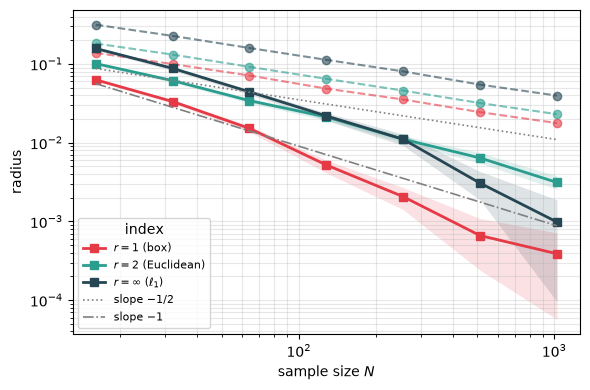

In [4]:
d = v6_6.data
Ns = np.array(d['Ns'], float)
fig, ax = plt.subplots(figsize=(6, 4))
cols = {1: '#e63946', 2: '#2a9d8f', np.inf: '#264653'}
for r in [1, 2, np.inf]:
    lab = {1: '$r=1$ (box)', 2: '$r=2$ (Euclidean)', np.inf: '$r=\\infty$ ($\\ell_1$)'}[r]
    ax.loglog(Ns, d['cert'][r], 'o--', color=cols[r], alpha=.6, lw=1.5)
    ax.loglog(Ns, d['star'][r], 's-', color=cols[r], lw=2, label=lab)
    lo, hi = d['star_band'][r]
    ax.fill_between(Ns, lo, hi, color=cols[r], alpha=.15, lw=0)
ax.loglog(Ns, .35 * Ns**-.5, ':', color='gray', lw=1.2, label=r'slope $-1/2$')
ax.loglog(Ns, .9 * Ns**-1.0, '-.', color='gray', lw=1.2, label=r'slope $-1$')
ax.set_xlabel('sample size $N$'); ax.set_ylabel('radius')
ax.legend(title='index', fontsize=8); ax.grid(alpha=.3, which='both')
fig.tight_layout(); fig.savefig(paths.figure('fig_rate.pdf'), bbox_inches='tight')
plt.show()

## V6.7 — $N\varepsilon^\star(N)$ approaches $c_r(p)$

The risk-optimal radius times $N$, with 90% bootstrap bands over draws, on the two sources of V6.4, for $N = 16,\dots,8192$; the dashed lines are the constants of Proposition 6.1. It reads the same computation as V6.4 (4000 draws per point; 90% intervals from eight independent batches), so the two cannot disagree.

In [5]:
v6_7 = calibration.v6_7()
v6_7

PASS  V6.7: N eps*(N) approaches c_r(p), N = 16 to 8192  [prop:rate]
    source 1, r=  1: c_r = 0.471;  N eps* = 1.07 1.06 0.95 0.73 0.55 0.46 0.45 0.46 0.46 0.48;  rel. error at 8192 2.8%  ok
    source 1, r=  2: c_r = 2.893;  N eps* = 1.72 2.01 2.28 2.52 2.73 2.85 2.68 2.73 2.85 2.76;  rel. error at 8192 4.7%  ok
    source 1, r=inf: c_r = 1.333;  N eps* = 2.81 2.83 3.00 2.94 2.54 1.60 1.34 1.24 1.30 1.32;  rel. error at 8192 1.2%  ok
    source 2, r=  1: c_r = 0.536;  N eps* = 0.85 0.89 0.83 0.64 0.55 0.52 0.53 0.52 0.53 0.52;  rel. error at 8192 3.2%  ok
    source 2, r=  2: c_r = 1.959;  N eps* = 1.62 1.70 1.87 1.84 1.94 1.98 1.90 1.89 1.94 1.93;  rel. error at 8192 1.5%  ok
    source 2, r=inf: c_r = 1.396;  N eps* = 2.54 2.51 2.39 1.92 1.49 1.37 1.32 1.34 1.38 1.39;  rel. error at 8192 0.3%  ok
  => N eps* at N = 8192 against c_r(p): +2.8%, -4.7%, -1.2%, -3.2%, -1.5%, -0.3%

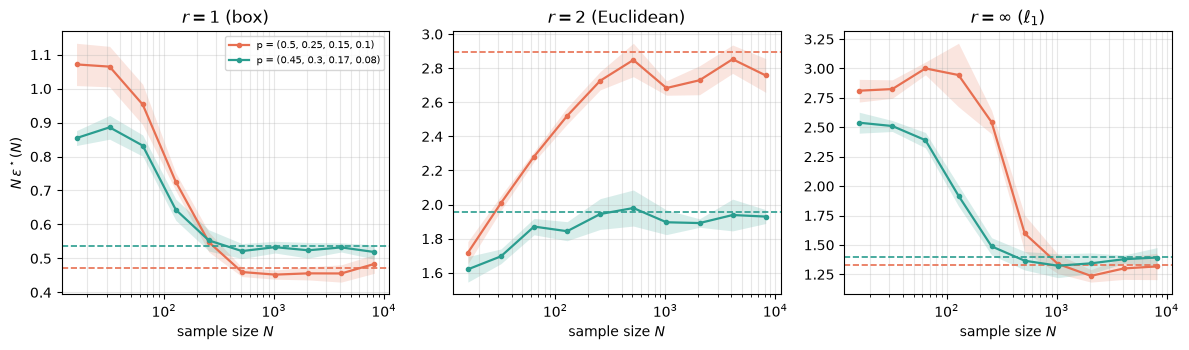

In [6]:
d = v6_7.data
Ns = np.array(d['Ns'], float)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True)
cols = ['#e76f51', '#2a9d8f']
for ax, (r, lab) in zip(axes, [(1, r'$r=1$ (box)'), (2, r'$r=2$ (Euclidean)'), (np.inf, r'$r=\infty$ ($\ell_1$)')]):
    for si, col in enumerate(cols):
        c = d['curves'][(si, str(r))]
        ax.semilogx(Ns, c['n_eps'], 'o-', color=col, lw=1.6, ms=3,
                    label='p = (' + ', '.join(f'{v:g}' for v in d['sources'][si]) + ')')
        ax.fill_between(Ns, c['lo'], c['hi'], color=col, alpha=.18, lw=0)
        ax.axhline(c['c'], color=col, ls='--', lw=1.2)
    ax.set_title(lab); ax.set_xlabel('sample size $N$'); ax.grid(alpha=.3, which='both')
axes[0].set_ylabel(r'$N\,\varepsilon^\star(N)$')
axes[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(paths.figure('fig_rate_constant.pdf'), bbox_inches='tight')
plt.show()

## V6.10 — the geometry adds nothing over shrinkage

At the corrected radius the family joins the shrinkage cluster, but that gain is adaptivity, not geometry. Given the same oracle tuning, uniform shrinkage toward $u$ wins or ties in every cell.

In [7]:
calibration.v6_10()

PASS  V6.10: the geometry adds nothing over shrinkage  [obs:geom]
    n=4 a=0.3 N=  8: shrink*=0.1213 family*=0.1205 ratio=0.993 best_r=inf HS=inf
    n=4 a=0.3 N= 32: shrink*=0.0362 family*=0.0369 ratio=1.020 best_r=2 HS=inf
    n=4 a=0.3 N=128: shrink*=0.0095 family*=0.0096 ratio=1.007 best_r=1 HS=inf
    n=4 a=1.0 N=  8: shrink*=0.1178 family*=0.1255 ratio=1.065 best_r=2 HS=inf
    n=4 a=1.0 N= 32: shrink*=0.0404 family*=0.0415 ratio=1.027 best_r=2 HS=0.0514
    n=4 a=1.0 N=128: shrink*=0.0117 family*=0.0119 ratio=1.016 best_r=2 HS=0.0125
    n=4 a=3.0 N=  8: shrink*=0.0743 family*=0.0825 ratio=1.111 best_r=2 HS=0.1205
    n=4 a=3.0 N= 32: shrink*=0.0304 family*=0.0322 ratio=1.058 best_r=2 HS=0.0388
    n=4 a=3.0 N=128: shrink*=0.0101 family*=0.0101 ratio=1.003 best_r=2 HS=0.0109
    n=8 a=0.3 N=  8: shrink*=0.2535 family*=0.2584 ratio=1.019 best_r=2 HS=inf
    n=8 a=0.3 N= 32: shrink*=0.0760 family*=0.0780 ratio=1.026 best_r=2 HS=inf
    n=8 a=0.3 N=128: shrink*=0.0232 family*=0.02

## V6.4 — the rate constant: $N\varepsilon^\star \to c_r(p)$

Regime (a) at large $N$, on two sources, with a control variate that removes the per-draw fluctuation of order $\varepsilon/\sqrt N$.

In [8]:
calibration.v6_4()  # slow: about 45 minutes on eight processes (the study V6.7 shares)

PASS  V6.4: the rate constant: N eps* converges to c_r(p)  [prop:rate]
    90% intervals from 8 independent batches of 500 draws
    source 1, r=  1: c_r = 0.471;  N eps* at N = [1024, 2048, 4096, 8192]: 0.45 [0.44, 0.47]; 0.46 [0.44, 0.48]; 0.46 [0.43, 0.48]; 0.48 [0.46, 0.51]   rel. error 0.04 -> 0.03  ok
    source 1, r=  2: c_r = 2.893;  N eps* at N = [1024, 2048, 4096, 8192]: 2.68 [2.64, 2.73]; 2.73 [2.64, 2.81]; 2.85 [2.77, 2.94]; 2.76 [2.66, 2.86]   rel. error 0.07 -> 0.05  ok
    source 1, r=inf: c_r = 1.333;  N eps* at N = [1024, 2048, 4096, 8192]: 1.34 [1.26, 1.42]; 1.24 [1.18, 1.29]; 1.30 [1.21, 1.39]; 1.32 [1.20, 1.43]   rel. error 0.00 -> 0.01  ok
    source 2, r=  1: c_r = 0.536;  N eps* at N = [1024, 2048, 4096, 8192]: 0.53 [0.52, 0.55]; 0.52 [0.50, 0.55]; 0.53 [0.52, 0.55]; 0.52 [0.50, 0.54]   rel. error 0.01 -> 0.03  ok
    source 2, r=  2: c_r = 1.959;  N eps* at N = [1024, 2048, 4096, 8192]: 1.90 [1.82, 1.97]; 1.89 [1.87, 1.92]; 1.94 [1.85, 2.03]; 1.93 [1.89, 1.97]  

## V6.3 — the rate constant from the derivatives at $\varepsilon = 0$

The linear and quadratic coefficients of the risk, $a_N$ and $2b_N$, estimated directly at $\varepsilon=0$ with a control variate, restricted to the good event $\{\min\hat p \ge \min p/2\}$. Sharper than V6.4, which reads the minimiser off a flat curve. Also shows the endpoint order-flip term dying out.

In [9]:
calibration.v6_3()  # slow: about two minutes

PASS  V6.3: the rate constant from the derivatives at eps = 0  [prop:rate]
    source 1, r=  1: c_r = 0.471; at N = 8192 c_N = 0.475 [0.469, 0.481]  ok
        N=256: c_N=0.519 a_N/a=1.190;  N=512: c_N=0.475 a_N/a=1.048;  N=1024: c_N=0.470 a_N/a=1.016;  N=2048: c_N=0.470 a_N/a=1.007;  N=4096: c_N=0.475 a_N/a=1.014;  N=8192: c_N=0.475 a_N/a=1.012
    source 1, r=  2: c_r = 2.893; at N = 8192 c_N = 2.881 [2.857, 2.904]  ok
        N=256: c_N=2.490 a_N/a=1.046;  N=512: c_N=2.692 a_N/a=1.023;  N=1024: c_N=2.770 a_N/a=1.006;  N=2048: c_N=2.821 a_N/a=0.998;  N=4096: c_N=2.864 a_N/a=1.001;  N=8192: c_N=2.881 a_N/a=1.001
    source 1, r=inf: c_r = 1.333; at N = 8192 c_N = 1.339 [1.323, 1.357]  ok
        N=256: c_N=2.472 a_N/a=2.088;  N=512: c_N=1.801 a_N/a=1.424;  N=1024: c_N=1.388 a_N/a=1.067;  N=2048: c_N=1.325 a_N/a=1.004;  N=4096: c_N=1.310 a_N/a=0.988;  N=8192: c_N=1.339 a_N/a=1.007
    source 2, r=  1: c_r = 0.536; at N = 8192 c_N = 0.539 [0.533, 0.545]  ok
        N=256: c_N=0.512 a_N/

## V6.9 — the local regime: near $u$ the risk-optimal radius is $N^{-1/2}$

Regime (b): $p = u + h\,d/\sqrt N$.

In [10]:
calibration.v6_9()  # slow: about twenty minutes

PASS  V6.9: the local regime: near u the risk-optimal radius is N^{-1/2}  [prop:rate]
    r=  1: slope -0.626 [-0.668, -0.533];  sqrt(N) eps* = 0.109 0.108 0.085 0.071 0.058 0.067 0.075   ok
    r=  2: slope -0.526 [-0.543, -0.511];  sqrt(N) eps* = 0.268 0.265 0.264 0.243 0.264 0.235 0.244   ok
    r=inf: slope -0.523 [-0.553, -0.496];  sqrt(N) eps* = 0.346 0.333 0.328 0.293 0.343 0.316 0.304   ok
  => slopes -0.63, -0.53, -0.52 (r = 1, 2, inf; want -0.5)

## V6.8 — uniform shrinkage: the constant, and the reductions against the family

The corrected shrinkage constant $N\beta^\star = (\tfrac1n\sum 1/p_i - 1)/\sum (p_i-1/n)^2/p_i$ against a derivative estimate, and the optimal risk reductions of the $r=2$ member and of uniform shrinkage on three sources.

In [11]:
calibration.v6_8()  # slow: about a minute

PASS  V6.8: uniform shrinkage: the constant, and the reductions against the family  [obs:geom]
    p = [0.5  0.25 0.15 0.1 ]: N beta* formula 11.20, estimate 11.17;  reduction x N^2: shrinkage 26.1 (est. 26.1), r = 2 22.4 (est. 22.2)  ok
    p = [0.45 0.3  0.17 0.08]: N beta* formula 10.05, estimate 10.00;  reduction x N^2: shrinkage 25.0 (est. 25.0), r = 2 15.2 (est. 15.2)  ok
    p = [0.7  0.11 0.1  0.09]: N beta* formula 7.07, estimate 7.04;  reduction x N^2: shrinkage 24.4 (est. 24.3), r = 2 50.8 (est. 49.1)  ok
  => corrected shrinkage constant confirmed; r = 2 beats shrinkage on (0.7, 0.11, 0.10, 0.09) only

## V6.5 — coverage at the two radii

How often the ball around $\hat p$ contains $p$, at the risk-optimal radius $c_r(p)/N$ and at the certificate radius $\varepsilon_{\mathrm{cert}}(N)$, for $N=16,\dots,1024$.

In [12]:
calibration.v6_5()

PASS  V6.5: coverage: the risk-optimal ball stops containing the truth  [prop:rate]
    r=  1: coverage at c_r/N 0.019 0.007 0.003 0.001 0.000 0.000 0.000;  at eps_cert 0.58 0.59 0.56 0.57 0.53 0.55 0.55  ok
    r=  2: coverage at c_r/N 0.548 0.270 0.121 0.047 0.017 0.006 0.003;  at eps_cert 0.58 0.55 0.54 0.54 0.55 0.55 0.55  ok
    r=inf: coverage at c_r/N 0.036 0.007 0.006 0.001 0.001 0.000 0.000;  at eps_cert 0.53 0.53 0.57 0.55 0.55 0.56 0.54  ok
  => N = 16..1024: coverage at c_r/N falls to 0.000, 0.003, 0.000 (r = 1, 2, inf); at eps_cert 0.55, 0.55, 0.54

## V6.2 — the rate constants, two ways

$c_r(p)$ with a numerical Hessian, as used by V6.3, V6.4, V6.6 and V6.9, against the explicit formulas, on the sources of V6.4/V6.3 and V6.8.

In [13]:
calibration.v6_2()

PASS  V6.2: the rate constants c_r(p), two ways  [prop:rate]
    p = [0.5  0.25 0.15 0.1 ]: c_1 = 0.471, c_2 = 2.893, c_inf = 1.333
    p = [0.45 0.3  0.17 0.08]: c_1 = 0.536, c_2 = 1.959, c_inf = 1.396
    p = [0.7  0.11 0.1  0.09]: c_1 = 0.335, c_2 = 5.237, c_inf = 1.544
  => max relative difference 9.0e-11 over three sources and three members